<a href="https://colab.research.google.com/github/jsansao/teic-20231/blob/main/Licao38_busca_semantica_nvidia_nim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Guia Prático de Busca Semântica e Embeddings com a API da NVIDIA NIM

Este notebook apresenta, passo a passo, a teoria e a prática da **Busca Semântica (Semantic Search)** utilizando modelos de *Embeddings* e *LLMs* da **NVIDIA NIM** (via SDK oficial da OpenAI), desde a implementação matemática do zero com **NumPy** até a indexação em banco vetorial com **FAISS**, visualização 2D do espaço vetorial, **Reranking** e **RAG (Retrieval-Augmented Generation)**.

---

### Roteiro do Notebook

1. **Configuração e Autenticação na NVIDIA NIM**
   - Leitura da chave em `chave.txt` e configuração dos modelos de *Embedding* (`1B` e `8B`) e *LLM*.
2. **Parte 1 — Fundamentos de Embeddings e Espaço Vetorial**
   - O que são *Embeddings*, geração do primeiro vetor na API, inspeção de dimensionalidade e norma $L_2$.
3. **Parte 2 — Métricas de Similaridade implementadas do zero com NumPy**
   - Similaridade de Cosseno, Produto Escalar (*Dot Product*) e Distância Euclidiana ($L_2$) na prática.
4. **Parte 3 — Embeddings Assimétricos na NVIDIA NIM (`passage` vs. `query`)**
   - A diferença entre vetorizar documentos longos para indexação e perguntas curtas para busca.
5. **Parte 4 — Base de Conhecimento, Mapa de Calor e Visualização 2D (PCA)**
   - Indexando 16 documentos corporativos em 4 categorias, plotando a matriz de similaridade e projetando os clusters semânticos em 2D com a *query* do usuário.
6. **Parte 5 — Busca Semântica (NumPy) vs. Busca Léxica por Palavras-Chave (TF-IDF)**
   - Implementação do motor de busca vetorial em NumPy e demonstração de casos onde a busca por palavras exatas falha, mas a busca semântica acerta pelo significado.
7. **Parte 6 — Indexação e Busca Escalonável com Banco Vetorial (FAISS)**
   - Construção de índices `IndexFlatIP` (Produto Interno/Cosseno) e `IndexFlatL2`, busca Top-$K$ e filtro por *threshold* de relevância.
8. **Parte 7 — Busca em Dois Estágios e Reranking (Reordenação de Resultados)**
   - *Bi-Encoder* rápido (`1B` $
ightarrow$ `8B`) e *LLM Cross-Attention Reranker* para desambiguar candidatos.
9. **Parte 8 — Pipeline Completo de Mini-RAG (Busca Semântica + Geração Fundamentada)**
   - Recuperação de contexto no FAISS + geração de resposta com citação de fontes e bloqueio de alucinação.

## 0. Configuração do Ambiente e Modelos da NVIDIA NIM

Assim como nos modelos de chat, o endpoint de embeddings da **NVIDIA NIM** segue o padrão da API da OpenAI (`client.embeddings.create`), aceitando parâmetros adicionais específicos de recuperação de informação através do campo `extra_body`.

Utilizaremos os seguintes modelos ativos no catálogo da NVIDIA NIM:
- **`nvidia/nemotron-3.5-embed-1b`**: Modelo de embeddings denso rápido e leve, gerando vetores de **2048 dimensões** normalizados.
- **`nvidia/nemotron-3.5-embed-8b`**: Modelo de embeddings de alta capacidade (8 bilhões de parâmetros), gerando vetores de **4096 dimensões** para reordenação de alta precisão.
- **`nvidia/nemotron-3.5-bolt-e4b`**: LLM rápido para as etapas de *Reranking Cross-Attention* e geração de respostas no *Mini-RAG*.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from openai import OpenAI


def carregar_chave_nim(caminho_arquivo: str = "chave.txt") -> str:
    """Lê a chave de API do arquivo chave.txt (suporta 'CHAVE = valor' ou apenas o valor)."""
    conteudo = Path(caminho_arquivo).read_text(encoding="utf-8").strip()
    if "=" in conteudo:
        return conteudo.split("=", 1)[1].strip()
    return conteudo


API_KEY = carregar_chave_nim("chave.txt")

client = OpenAI(
    base_url="https://integrate.api.nvidia.com/v1",
    api_key=API_KEY,
)

MODELO_EMBED_1B = "nvidia/nemotron-3.5-embed-1b"
MODELO_EMBED_8B = "nvidia/nemotron-3.5-embed-8b"
MODELO_LLM = "nvidia/nemotron-3.5-bolt-e4b"

print(f"Chave carregada com sucesso! Prefixo: {API_KEY[:10]}...")
print(f"Modelo de Embedding Padrão (1B): {MODELO_EMBED_1B}")
print(f"Modelo de Embedding Denso  (8B): {MODELO_EMBED_8B}")
print(f"Modelo LLM (RAG / Reranking)   : {MODELO_LLM}")

Chave carregada com sucesso! Prefixo: nvapi-2gUS...
Modelo de Embedding Padrão (1B): nvidia/nemotron-3.5-embed-1b
Modelo de Embedding Denso  (8B): nvidia/nemotron-3.5-embed-8b
Modelo LLM (RAG / Reranking)   : nvidia/nemotron-3.5-bolt-e4b


---
# Parte 1: O que são Embeddings? (Anatomia de um Vetor Semântico)

Na busca tradicional (léxica), os computadores comparam strings caractere por caractere ou contam a frequência de palavras exatas. O problema é que **"automóvel"** e **"carro"** não compartilham nenhuma letra em comum, embora signifiquem a mesma coisa; por outro lado, **"banco"** (assento de praça) e **"banco"** (instituição financeira) têm exatamente a mesma grafia, mas significados distintos.

Um **Modelo de Embedding** resolve esse problema transformando qualquer trecho de texto em um **vetor numérico denso** $\mathbf{v} \in \mathbb{R}^d$ (por exemplo, uma lista de $2048$ números reais), treinado de forma que:
- Textos com **significados semelhantes** são mapeados para **direções próximas** no espaço vetorial;
- Textos sobre **assuntos desconexos** ficam **distantes** (quase ortogonais) no espaço vetorial.

Vamos gerar nosso primeiro embedding na NVIDIA NIM e inspecionar sua anatomia!

In [2]:
texto_exemplo = "A inteligência artificial generativa está transformando o desenvolvimento de software."

resposta_emb = client.embeddings.create(
    input=[texto_exemplo],
    model=MODELO_EMBED_1B,
    encoding_format="float",
    extra_body={"input_type": "passage", "truncate": "NONE"},
)

vetor = np.array(resposta_emb.data[0].embedding, dtype=np.float32)
norma_l2 = np.linalg.norm(vetor)

print("=== ANATOMIA DO RETORNO DA API DE EMBEDDINGS ===")
print(f"Texto original        : {texto_exemplo!r}")
print(f"Modelo utilizado      : {resposta_emb.model}")
print(f"Tokens consumidos     : {resposta_emb.usage.prompt_tokens} tokens")
print(f"Dimensão do vetor (d) : {vetor.shape[0]} dimensões")
print(f"Tipo numérico         : {vetor.dtype}")
print(f"Norma L2 (||v||_2)    : {norma_l2:.6f}  (Vetor unitário / normalizado!)")
print(f"Mínimo / Máximo       : [{vetor.min():.4f}, {vetor.max():.4f}]")
print(f"Primeiros 10 valores  : {np.round(vetor[:10], 4)}")

=== ANATOMIA DO RETORNO DA API DE EMBEDDINGS ===
Texto original        : 'A inteligência artificial generativa está transformando o desenvolvimento de software.'
Modelo utilizado      : nvidia/nemotron-3.5-embed-1b
Tokens consumidos     : 17 tokens
Dimensão do vetor (d) : 2048 dimensões
Tipo numérico         : float32
Norma L2 (||v||_2)    : 1.000019  (Vetor unitário / normalizado!)
Mínimo / Máximo       : [-0.0728, 0.1337]
Primeiros 10 valores  : [ 0.1337 -0.0005 -0.0254  0.0185  0.0039  0.0196  0.033   0.0017 -0.0202
  0.0089]


---
# Parte 2: Métricas de Similaridade e Distância no Espaço Vetorial (NumPy)

Dados dois vetores $\mathbf{u}, \mathbf{v} \in \mathbb{R}^d$, existem três formas clássicas de medir o quão próximos eles estão:

| Métrica | Fórmula Matemática | Interpretação |
| :--- | :--- | :--- |
| **1. Similaridade de Cosseno** | $$\text{cos}(\theta) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\|_2 \, \|\mathbf{v}\|_2}$$ | Mede o cosseno do ângulo entre os vetores, variando de $-1$ (opostos) a $+1$ (idênticos). **Quanto maior, mais similar.** |
| **2. Produto Escalar (*Dot Product*)** | $$\mathbf{u} \cdot \mathbf{v} = \sum_{i=1}^{d} u_i v_i$$ | Soma dos produtos coordenada a coordenada. Como os vetores da NVIDIA NIM já vêm normalizados ($\|\mathbf{u}\|_2 = \|\mathbf{v}\|_2 = 1$), o **Produto Escalar é exatamente igual à Similaridade de Cosseno**, mas exige menos operações! |
| **3. Distância Euclidiana ($L_2$)** | $$d_{L_2}(\mathbf{u}, \mathbf{v}) = \|\mathbf{u} - \mathbf{v}\|_2 = \sqrt{\sum_{i=1}^{d} (u_i - v_i)^2}$$ | Distância em linha reta entre as extremidades dos vetores. **Quanto menor (mais próximo de $0$), mais similar.** Para vetores unitários, vale a identidade exata: $d_{L_2}^2 = 2(1 - \cos\theta)$. |

Vamos implementar essas 3 métricas do zero usando apenas **NumPy** e compará-las em quatro frases!

In [3]:
# Implementação das 3 métricas do zero com NumPy
def similaridade_cosseno(u: np.ndarray, v: np.ndarray) -> float:
    return float(np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v)))


def produto_escalar(u: np.ndarray, v: np.ndarray) -> float:
    return float(np.dot(u, v))


def distancia_euclidiana(u: np.ndarray, v: np.ndarray) -> float:
    return float(np.linalg.norm(u - v))


# Frase base e 3 frases de comparação (parafraseada, tema próximo e tema totalmente diferente)
frases_teste = [
    "Como posso redefinir minha senha de acesso ao portal corporativo?",               # [0] Frase Âncora
    "Esqueci minha credencial de login no sistema da empresa, quero trocá-la.",       # [1] Paráfrase (mesma intenção, palavras diferentes)
    "A política de segurança exige autenticação multifator (MFA) no celular.",        # [2] Mesmo domínio (Segurança), intenção diferente
    "A receita tradicional de pão de queijo mineiro leva polvilho azedo e queijo.",   # [3] Domínio completamente desconexo
]

resp_frases = client.embeddings.create(
    input=frases_teste,
    model=MODELO_EMBED_1B,
    encoding_format="float",
    extra_body={"input_type": "passage", "truncate": "NONE"},
)
vetores_frases = np.array([item.embedding for item in resp_frases.data], dtype=np.float32)

vetor_ancora = vetores_frases[0]
print(f"Frase Âncora: {frases_teste[0]!r}\n")

linhas_metricas = []
for idx in range(1, len(frases_teste)):
    v_comp = vetores_frases[idx]
    cos_sim = similaridade_cosseno(vetor_ancora, v_comp)
    dot_sim = produto_escalar(vetor_ancora, v_comp)
    l2_dist = distancia_euclidiana(vetor_ancora, v_comp)
    linhas_metricas.append({
        "Frase Comparada": frases_teste[idx],
        "Cosseno (↑)": round(cos_sim, 4),
        "Dot Product (↑)": round(dot_sim, 4),
        "Distância L2 (↓)": round(l2_dist, 4),
        "2*(1 - cos) == L2²": round(2 * (1 - cos_sim), 4) == round(l2_dist**2, 4),
    })

df_metricas = pd.DataFrame(linhas_metricas)
print(df_metricas.to_string(index=False))

Frase Âncora: 'Como posso redefinir minha senha de acesso ao portal corporativo?'

                                                             Frase Comparada  Cosseno (↑)  Dot Product (↑)  Distância L2 (↓)  2*(1 - cos) == L2²
    Esqueci minha credencial de login no sistema da empresa, quero trocá-la.       0.7355           0.7354            0.7274                True
     A política de segurança exige autenticação multifator (MFA) no celular.       0.4879           0.4879            1.0120                True
A receita tradicional de pão de queijo mineiro leva polvilho azedo e queijo.       0.3200           0.3200            1.1662                True


---
# Parte 3: Embeddings Assimétricos na NVIDIA NIM (`passage` vs. `query`)

Na busca semântica real, os textos que estamos comparando possuem naturezas **assimétricas**:
- **Consulta (`query`):** Geralmente é uma pergunta curta, vaga ou incompleta (ex.: *"reembolso de viagem"* ou *"como pedir férias?"*).
- **Documento (`passage`):** É um parágrafo ou artigo explicativo contendo fatos detalhados e respostas (ex.: *"De acordo com a norma RH-04, o colaborador deve registrar a solicitação de descanso anual com 30 dias de antecedência..."*).

Os modelos da NVIDIA NIM são treinados com prefixos/adaptadores internos específicos para cada papel, controlados via `extra_body={"input_type": ...}`:
- Use **`"input_type": "passage"`** ao indexar os documentos da sua base de conhecimento;
- Use **`"input_type": "query"`** no momento em que o usuário digita uma pergunta no buscador.

Vamos encapsular essa boa prática em duas funções reutilizáveis e verificar como o modo assimétrico melhora o contraste da busca!

In [4]:
def gerar_embeddings_documentos(textos: list[str], modelo: str = MODELO_EMBED_1B) -> np.ndarray:
    """Vetoriza uma lista de documentos/passagens para indexação (input_type='passage')."""
    resposta = client.embeddings.create(
        input=textos,
        model=modelo,
        encoding_format="float",
        extra_body={"input_type": "passage", "truncate": "NONE"},
    )
    return np.array([item.embedding for item in resposta.data], dtype=np.float32)


def gerar_embedding_query(pergunta: str, modelo: str = MODELO_EMBED_1B) -> np.ndarray:
    """Vetoriza uma consulta/pergunta do usuário para busca (input_type='query')."""
    resposta = client.embeddings.create(
        input=[pergunta],
        model=modelo,
        encoding_format="float",
        extra_body={"input_type": "query", "truncate": "NONE"},
    )
    return np.array(resposta.data[0].embedding, dtype=np.float32)


# Verificando que o mesmo texto gera vetores distintos quando marcado como 'query' vs 'passage'
texto_curto = "política de home office e trabalho remoto"
v_como_query = gerar_embedding_query(texto_curto)
v_como_passage = gerar_embeddings_documentos([texto_curto])[0]

print(f"Similaridade entre o mesmo texto codificado como 'query' vs 'passage': {np.dot(v_como_query, v_como_passage):.4f}")
print("-> Note que não é 1.0! O modelo projeta queries e passagens em subespaços otimizados para recuperação assimétrica.")

Similaridade entre o mesmo texto codificado como 'query' vs 'passage': 0.6578
-> Note que não é 1.0! O modelo projeta queries e passagens em subespaços otimizados para recuperação assimétrica.


---
# Parte 4: Base de Conhecimento Corporativa e Visualização do Espaço Semântico

Para explorar a busca semântica de forma visual e prática, vamos construir uma **Base de Conhecimento Corporativa** com **16 documentos** distribuídos em **4 departamentos**:
1. **Segurança & Acesso (SEC)**
2. **Recursos Humanos & Benefícios (RH)**
3. **Finanças & Reembolsos (FIN)**
4. **Engenharia & Cloud (ENG)**

Em seguida, vamos:
1. Vetorizar todos os 16 documentos em uma única chamada em lote (*batch*) à API da NVIDIA NIM;
2. Plotar o **Mapa de Calor (Heatmap)** da matriz de similaridade $16 \times 16$;
3. Reduzir a dimensionalidade de **2048 dimensões para 2 dimensões com PCA** para visualizar os clusters semânticos e onde uma *query* do usuário aterrissa no gráfico!

In [5]:
base_documentos = [
    # Categoria 1: Segurança & Acesso (SEC)
    {"id": "SEC-01", "categoria": "Segurança", "texto": "Para desbloquear sua conta ou redefinir a senha da rede corporativa, acesse o portal de autoatendimento e valide o token enviado por SMS."},
    {"id": "SEC-02", "categoria": "Segurança", "texto": "Todo acesso externo aos servidores de produção exige conexão ativa na VPN corporativa com autenticação multifator (MFA) habilitada."},
    {"id": "SEC-03", "categoria": "Segurança", "texto": "E-mails suspeitos solicitando dados confidenciais ou links desconhecidos devem ser reportados imediatamente ao time de resposta a incidentes de phishing."},
    {"id": "SEC-04", "categoria": "Segurança", "texto": "Notebooks corporativos possuem criptografia de disco completa BitLocker e bloqueio automático de tela após 5 minutos de inatividade."},

    # Categoria 2: Recursos Humanos & Benefícios (RH)
    {"id": "RH-01", "categoria": "RH", "texto": "O regime de trabalho híbrido permite que colaboradores trabalhem remotamente de casa (home office) até três dias por semana mediante alinhamento com o gestor."},
    {"id": "RH-02", "categoria": "RH", "texto": "As férias anuais de 30 dias podem ser parceladas em até três períodos, desde que um deles tenha no mínimo 14 dias corridos."},
    {"id": "RH-03", "categoria": "RH", "texto": "O plano de saúde empresarial cobre consultas médicas, exames laboratoriais e internações sem coparticipação para titulares e dependentes diretos."},
    {"id": "RH-04", "categoria": "RH", "texto": "O auxílio-educação reembolsa até 70% da mensalidade de cursos de pós-graduação, mestrado e certificações técnicas alinhadas à carreira."},

    # Categoria 3: Finanças & Reembolsos (FIN)
    {"id": "FIN-01", "categoria": "Finanças", "texto": "Despesas de alimentação e táxi em viagens a trabalho são reembolsadas em até 5 dias úteis após o envio dos comprovantes fiscais no sistema ERP."},
    {"id": "FIN-02", "categoria": "Finanças", "texto": "Compras de softwares, licenças SaaS ou equipamentos acima de R$ 2.000 exigem abertura de requisição de compra e aprovação da diretoria financeira."},
    {"id": "FIN-03", "categoria": "Finanças", "texto": "Notas fiscais de prestadores de serviço PJ devem ser emitidas até o dia 20 de cada mês para processamento no ciclo de contas a pagar."},
    {"id": "FIN-04", "categoria": "Finanças", "texto": "O cartão corporativo é destinado exclusivamente a gastos de representação comercial e hospedagem, sendo vedado o saque em espécie."},

    # Categoria 4: Engenharia & Cloud (ENG)
    {"id": "ENG-01", "categoria": "Engenharia", "texto": "Todos os microsserviços em Python devem rodar em contêineres Docker orquestrados no cluster Kubernetes com limites de CPU e memória definidos."},
    {"id": "ENG-02", "categoria": "Engenharia", "texto": "O pipeline de CI/CD no GitLab executa testes unitários automatizados, análise estática de código e verificação de vulnerabilidades antes do deploy."},
    {"id": "ENG-03", "categoria": "Engenharia", "texto": "Bancos de dados relacionais PostgreSQL em produção realizam snapshots incrementais a cada hora com replicação multi-zona na nuvem."},
    {"id": "ENG-04", "categoria": "Engenharia", "texto": "Chaves de API e credenciais de banco nunca devem ser salvas no repositório Git; utilize sempre o cofre de segredos HashiCorp Vault."},
]

df_docs = pd.DataFrame(base_documentos)

# Gerando embeddings de todos os 16 documentos em uma única requisição em lote (batch)
matriz_embeddings = gerar_embeddings_documentos(df_docs["texto"].tolist(), modelo=MODELO_EMBED_1B)
print(f"Matriz de embeddings gerada com sucesso! Shape: {matriz_embeddings.shape} (16 documentos x 2048 dimensões)")

Matriz de embeddings gerada com sucesso! Shape: (16, 2048) (16 documentos x 2048 dimensões)


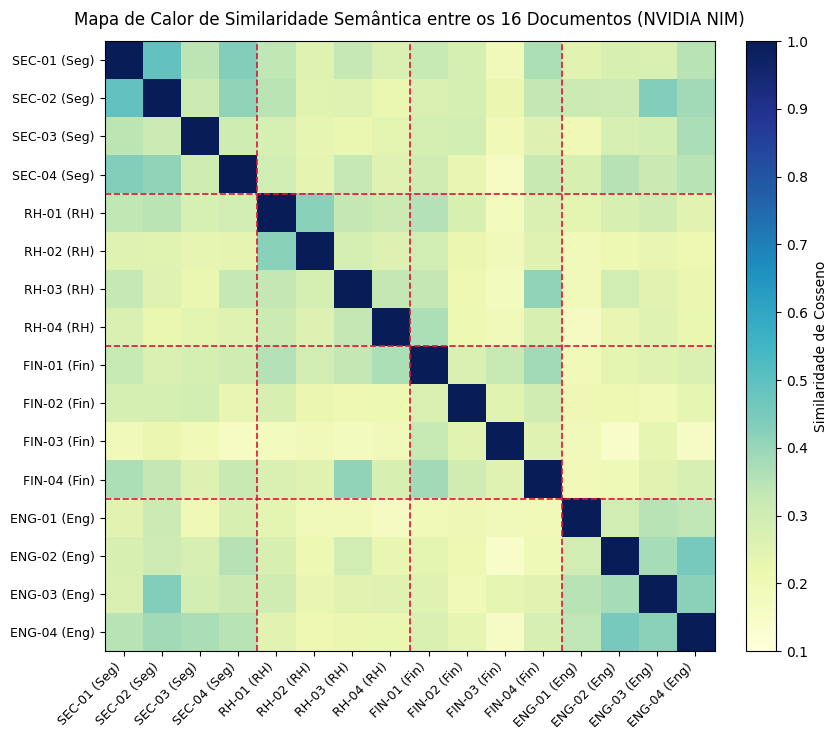

In [6]:
# Calculando a Matriz de Similaridade de Cosseno (16 x 16) via multiplicação matricial: M @ M.T
matriz_similaridade = matriz_embeddings @ matriz_embeddings.T

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(matriz_similaridade, cmap="YlGnBu", vmin=0.1, vmax=1.0)

rotulos = [f"{row['id']} ({row['categoria'][:3]})" for _, row in df_docs.iterrows()]
ax.set_xticks(range(len(rotulos)))
ax.set_yticks(range(len(rotulos)))
ax.set_xticklabels(rotulos, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(rotulos, fontsize=9)

# Linhas divisórias entre os 4 blocos de departamentos
for pos in [3.5, 7.5, 11.5]:
    ax.axhline(pos, color="crimson", linestyle="--", linewidth=1.2)
    ax.axvline(pos, color="crimson", linestyle="--", linewidth=1.2)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Similaridade de Cosseno")
ax.set_title("Mapa de Calor de Similaridade Semântica entre os 16 Documentos (NVIDIA NIM)", fontsize=12, pad=12)
plt.tight_layout()
plt.show()

Observe no **Mapa de Calor** acima como os quadrados $4 \times 4$ ao longo da diagonal principal (delimitados pelas linhas tracejadas vermelhas) apresentam cores mais escuras (maior similaridade entre documentos do mesmo departamento). Além disso, veja como o documento **`ENG-04`** (sobre guardar chaves de API no cofre de segredos) também apresenta similaridade cruzada com o bloco de **Segurança (`SEC`)** — capturando perfeitamente a interseção semântica entre Engenharia e Segurança!

### Visualização 2D dos Clusters Semânticos com PCA
Agora vamos projetar os vetores de $2048$ dimensões em um plano 2D usando **PCA (Principal Component Analysis)** e projetar também uma consulta do usuário para ver onde ela se posiciona geometricamente.

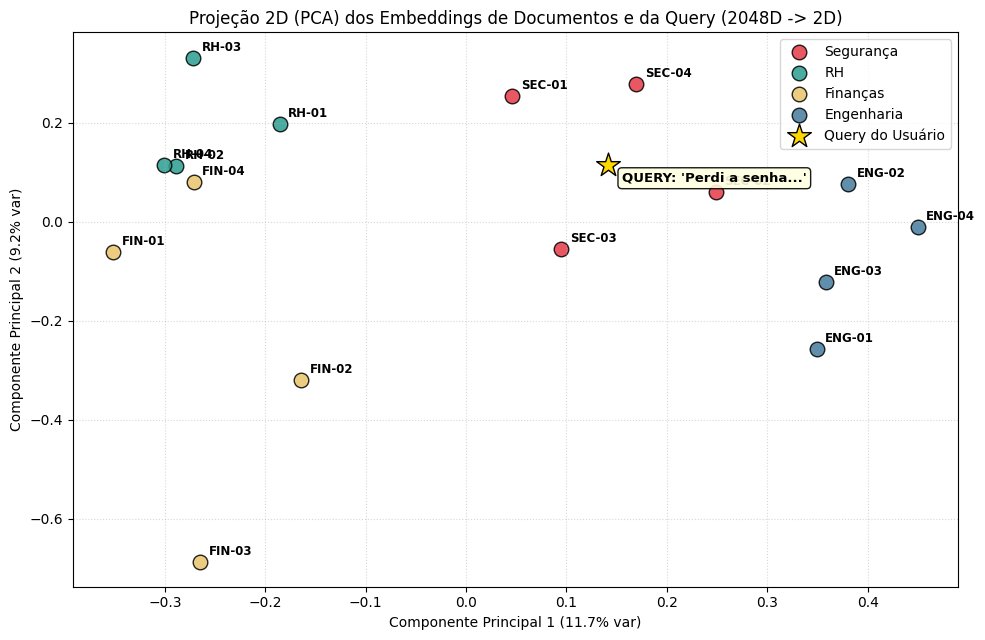

In [7]:
from sklearn.decomposition import PCA

pergunta_visual = "Perdi a senha do meu notebook e não consigo logar no sistema, como recupero?"
vetor_pergunta_vis = gerar_embedding_query(pergunta_visual, modelo=MODELO_EMBED_1B)

# Ajusta o PCA nos documentos e transforma tanto os documentos quanto a query
pca = PCA(n_components=2, random_state=42)
coords_docs_2d = pca.fit_transform(matriz_embeddings)
coord_query_2d = pca.transform(vetor_pergunta_vis.reshape(1, -1))[0]

cores_categoria = {
    "Segurança": "#e63946",
    "RH": "#2a9d8f",
    "Finanças": "#e9c46a",
    "Engenharia": "#457b9d",
}

fig, ax = plt.subplots(figsize=(10, 6.5))

for categoria, cor in cores_categoria.items():
    mascara = df_docs["categoria"] == categoria
    pts = coords_docs_2d[mascara]
    ax.scatter(pts[:, 0], pts[:, 1], label=categoria, color=cor, s=110, alpha=0.85, edgecolors="black")

for idx, row in df_docs.iterrows():
    ax.annotate(
        row["id"],
        (coords_docs_2d[idx, 0], coords_docs_2d[idx, 1]),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold",
    )

# Plotando a Query do usuário como uma estrela dourada/preta
ax.scatter(
    coord_query_2d[0],
    coord_query_2d[1],
    color="gold",
    edgecolors="black",
    marker="*",
    s=320,
    zorder=5,
    label="Query do Usuário",
)
ax.annotate(
    "QUERY: 'Perdi a senha...'",
    (coord_query_2d[0], coord_query_2d[1]),
    xytext=(10, -12),
    textcoords="offset points",
    fontsize=9.5,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="black", alpha=0.9),
)

ax.set_title("Projeção 2D (PCA) dos Embeddings de Documentos e da Query (2048D -> 2D)", fontsize=12)
ax.set_xlabel(f"Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
ax.set_ylabel(f"Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="best", frameon=True)
plt.tight_layout()
plt.show()

---
# Parte 5: Busca Semântica do Zero (NumPy) vs. Busca Léxica (TF-IDF)

Vamos agora construir nosso motor de busca semântica com **NumPy** e compará-lo diretamente com a busca tradicional baseada em palavras-chave (**TF-IDF** do `scikit-learn`).

Para testar o poder real da busca semântica, faremos perguntas que **não repetem nenhuma palavra substantiva** presente nos documentos originais (usando sinônimos e expressões do dia a dia):
1. *"Posso cumprir minha jornada de trabalho da minha residência alguns dias?"* (No documento `RH-01` está escrito *"remotamente de casa / home office"*).
2. *"Paguei um almoço com cliente e corrida de Uber na viagem, como recebo o dinheiro de volta?"* (No documento `FIN-01` está escrito *"Despesas de alimentação e táxi... são reembolsadas"*).
3. *"Esqueci a palavra-passe para entrar no computador, como destravo?"* (No documento `SEC-01` está escrito *"desbloquear sua conta ou redefinir a senha"*).

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity as sklearn_cosine

# 1. Configurando o buscador Léxico (TF-IDF por palavras exatas)
vetorizador_tfidf = TfidfVectorizer(lowercase=True)
matriz_tfidf_docs = vetorizador_tfidf.fit_transform(df_docs["texto"])


def buscar_lexico_tfidf(query: str, top_k: int = 2) -> list[dict]:
    q_vec = vetorizador_tfidf.transform([query])
    scores = sklearn_cosine(q_vec, matriz_tfidf_docs).flatten()
    indices_top = np.argsort(scores)[::-1][:top_k]
    return [
        {"id": df_docs.iloc[i]["id"], "score_tfidf": round(float(scores[i]), 4), "texto": df_docs.iloc[i]["texto"]}
        for i in indices_top
    ]


# 2. Configurando o buscador Semântico Denso (Do zero com NumPy + NVIDIA NIM)
def buscar_semantico_numpy(query: str, top_k: int = 2) -> list[dict]:
    vetor_q = gerar_embedding_query(query, modelo=MODELO_EMBED_1B)
    # Produto escalar matricial entre todos os documentos (16, 2048) e a query (2048,)
    scores = matriz_embeddings @ vetor_q
    indices_top = np.argsort(scores)[::-1][:top_k]
    return [
        {"id": df_docs.iloc[i]["id"], "score_semantico": round(float(scores[i]), 4), "texto": df_docs.iloc[i]["texto"]}
        for i in indices_top
    ]


consultas_comparacao = [
    ("Posso cumprir minha jornada da minha residência alguns dias?", "RH-01"),
    ("Gastei com Uber e restaurante visitando um cliente, como recebo o valor de volta?", "FIN-01"),
    ("A faculdade de especialização que estou cursando tem algum subsídio da empresa?", "RH-04"),
]

for pergunta, id_esperado in consultas_comparacao:
    res_lex = buscar_lexico_tfidf(pergunta, top_k=1)[0]
    res_sem = buscar_semantico_numpy(pergunta, top_k=1)[0]
    print("=" * 95)
    print(f"PERGUNTA DO USUÁRIO : {pergunta}")
    print(f"DOCUMENTO ESPERADO  : {id_esperado}")
    print(f"  [Busca Léxica TF-IDF] -> Top-1: {res_lex['id']} (score={res_lex['score_tfidf']:.4f}) | Acertou? {res_lex['id'] == id_esperado}")
    print(f"  [Busca Semântica NIM] -> Top-1: {res_sem['id']} (score={res_sem['score_semantico']:.4f}) | Acertou? {res_sem['id'] == id_esperado}")
    print(f"  Texto recuperado (NIM): {res_sem['texto']}")

PERGUNTA DO USUÁRIO : Posso cumprir minha jornada da minha residência alguns dias?
DOCUMENTO ESPERADO  : RH-01
  [Busca Léxica TF-IDF] -> Top-1: RH-02 (score=0.2479) | Acertou? False
  [Busca Semântica NIM] -> Top-1: RH-01 (score=0.3091) | Acertou? True
  Texto recuperado (NIM): O regime de trabalho híbrido permite que colaboradores trabalhem remotamente de casa (home office) até três dias por semana mediante alinhamento com o gestor.
PERGUNTA DO USUÁRIO : Gastei com Uber e restaurante visitando um cliente, como recebo o valor de volta?
DOCUMENTO ESPERADO  : FIN-01
  [Busca Léxica TF-IDF] -> Top-1: RH-02 (score=0.1957) | Acertou? False
  [Busca Semântica NIM] -> Top-1: FIN-01 (score=0.3340) | Acertou? True
  Texto recuperado (NIM): Despesas de alimentação e táxi em viagens a trabalho são reembolsadas em até 5 dias úteis após o envio dos comprovantes fiscais no sistema ERP.
PERGUNTA DO USUÁRIO : A faculdade de especialização que estou cursando tem algum subsídio da empresa?
DOCUMENTO ES

---
# Parte 6: Indexação e Busca Escalonável com Banco Vetorial (FAISS)

Multiplicar matrizes diretamente com NumPy (`matriz_embeddings @ vetor_q`) funciona muito bem para algumas centenas ou milhares de documentos. Porém, quando escalamos para **centenas de milhares ou milhões de documentos**, precisamos de estruturas de índice especializadas como o **FAISS (Facebook AI Similarity Search)**.

O FAISS (escrito em C++ com bindings em Python) oferece:
- **`faiss.IndexFlatIP` (*Inner Product*):** Busca exata por Produto Interno (equivalente à Similaridade de Cosseno quando os vetores estão normalizados).
- **`faiss.IndexFlatL2`:** Busca exata pela menor Distância Euclidiana quadrática ($L_2^2$).
- **Índices Aproximados (ANN — *Approximate Nearest Neighbors*):** Como `IndexIVFFlat` (particionamento em células de Voronoi) e `IndexHNSWFlat` (grafos navegáveis em mundo pequeno) para buscas sub-milissegundo em milhões de vetores.

Abaixo, construímos um índice vetorial completo com **FAISS** suportando filtragem por metadados e corte por limiar mínimo de relevância (*threshold*).

In [11]:
!pip install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 11.8 MB/s  0:00:01


In [12]:
import faiss


class IndiceVetorialFAISS:
    """Encapsula um índice FAISS (IndexFlatIP) integrado aos metadados dos documentos."""

    def __init__(self, dimensao: int):
        self.dimensao = dimensao
        # IndexFlatIP calcula o Produto Interno (Cosseno para vetores L2-normalizados)
        self.index = faiss.IndexFlatIP(dimensao)
        self.metadados: list[dict] = []

    def adicionar_documentos(self, vetores: np.ndarray, documentos: list[dict]):
        vetores_f32 = np.ascontiguousarray(vetores, dtype=np.float32)
        # Garante normalização L2 no próprio FAISS
        faiss.normalize_L2(vetores_f32)
        self.index.add(vetores_f32)
        self.metadados.extend(documentos)

    def buscar(
        self,
        query: str,
        top_k: int = 3,
        threshold_minimo: float = 0.25,
        filtro_categoria: str | None = None,
    ) -> list[dict]:
        vetor_q = gerar_embedding_query(query, modelo=MODELO_EMBED_1B).reshape(1, -1)
        vetor_q = np.ascontiguousarray(vetor_q, dtype=np.float32)
        faiss.normalize_L2(vetor_q)

        # Buscamos mais candidatos caso haja filtro de categoria pós-busca
        k_busca = len(self.metadados) if filtro_categoria else top_k
        scores, indices = self.index.search(vetor_q, k_busca)

        resultados = []
        for score, idx in zip(scores[0], indices[0]):
            if idx == -1 or score < threshold_minimo:
                continue
            doc = self.metadados[idx]
            if filtro_categoria and doc["categoria"].lower() != filtro_categoria.lower():
                continue
            resultados.append({
                "id": doc["id"],
                "categoria": doc["categoria"],
                "similaridade": round(float(score), 4),
                "texto": doc["texto"],
            })
            if len(resultados) >= top_k:
                break
        return resultados


# Instanciando e populando o índice FAISS com os 16 documentos (dimensão = 2048)
banco_faiss = IndiceVetorialFAISS(dimensao=matriz_embeddings.shape[1])
banco_faiss.adicionar_documentos(matriz_embeddings, base_documentos)

print(f"Total de vetores indexados no FAISS (ntotal): {banco_faiss.index.ntotal}")

# Teste 1: Busca global Top-3 no FAISS
consulta_faiss = "Onde devo armazenar senhas de banco de dados usadas pelos sistemas em produção?"
print(f"\n=== BUSCA GLOBAL NO FAISS: {consulta_faiss!r} ===")
for rank, item in enumerate(banco_faiss.buscar(consulta_faiss, top_k=3), 1):
    print(f"#{rank} [{item['id']} | {item['categoria']}] (sim={item['similaridade']:.4f}) -> {item['texto']}")

# Teste 2: Teste de Threshold com pergunta fora do escopo (Irrelevante)
consulta_fora = "Qual a escalação da seleção brasileira na final da Copa de 2002?"
res_fora = banco_faiss.buscar(consulta_fora, top_k=3, threshold_minimo=0.35)
print(f"\n=== TESTE DE THRESHOLD (PERGUNTA FORA DO ESCOPO): {consulta_fora!r} ===")
print(f"Resultados acima do threshold de 0.35: {len(res_fora)} documentos encontrados (evita trazer ruído!)")

Total de vetores indexados no FAISS (ntotal): 16

=== BUSCA GLOBAL NO FAISS: 'Onde devo armazenar senhas de banco de dados usadas pelos sistemas em produção?' ===
#1 [ENG-04 | Engenharia] (sim=0.5282) -> Chaves de API e credenciais de banco nunca devem ser salvas no repositório Git; utilize sempre o cofre de segredos HashiCorp Vault.
#2 [ENG-03 | Engenharia] (sim=0.3391) -> Bancos de dados relacionais PostgreSQL em produção realizam snapshots incrementais a cada hora com replicação multi-zona na nuvem.
#3 [SEC-02 | Segurança] (sim=0.3232) -> Todo acesso externo aos servidores de produção exige conexão ativa na VPN corporativa com autenticação multifator (MFA) habilitada.

=== TESTE DE THRESHOLD (PERGUNTA FORA DO ESCOPO): 'Qual a escalação da seleção brasileira na final da Copa de 2002?' ===
Resultados acima do threshold de 0.35: 0 documentos encontrados (evita trazer ruído!)


---
# Parte 7: Busca em Dois Estágios e Reranking (Reordenação de Resultados)

Em sistemas de busca semântica de alta precisão, é muito comum adotar uma **Arquitetura em Dois Estágios (Two-Stage Retrieval)**:

```
[Corpus com milhares de docs]
       │
       ▼  1º Estágio: Retrieval Rápido (FAISS + Modelo Leve 1B: nemotron-3.5-embed-1b)
[Top-5 Candidatos Recuperados]
       │
       ▼  2º Estágio: Reranking de Alta Precisão (Modelo Denso 8B + LLM Cross-Attention)
[Top-2 Resultados Reordenados]
```

Por que fazer isso?
1. **No 1º estágio**, usamos um modelo leve (`1B`, 2048 dimensões) para varrer toda a base rapidamente e separar os $N$ candidatos mais promissores (alta revocação / *recall*).
2. **No 2º estágio**, aplicamos um avaliador mais pesado apenas sobre esses poucos candidatos:
   - **Reranking Denso (`8B`):** Re-vetorizamos a pergunta e os 5 candidatos usando o `nvidia/nemotron-3.5-embed-8b` (4096 dimensões); e/ou
   - **LLM Cross-Attention Reranker:** Passamos a pergunta e os candidatos juntos para o LLM (`nvidia/nemotron-3.5-bolt-e4b`), que lê as nuances semânticas com atenção cruzada completa (*cross-attention*) e atribui uma nota de relevância de `0` a `10`.

In [13]:
def busca_com_reranking(pergunta: str, top_k_inicial: int = 4, top_k_final: int = 2) -> pd.DataFrame:
    # 1º Estágio: Recuperação rápida no FAISS com modelo 1B
    candidatos = banco_faiss.buscar(pergunta, top_k=top_k_inicial, threshold_minimo=0.10)

    # 2º Estágio (Parte A): Re-pontuação densa com o modelo 8B (4096 dimensões)
    vetor_q_8b = gerar_embedding_query(pergunta, modelo=MODELO_EMBED_8B)
    vetores_docs_8b = gerar_embeddings_documentos([c["texto"] for c in candidatos], modelo=MODELO_EMBED_8B)
    scores_8b = vetores_docs_8b @ vetor_q_8b

    # 2º Estágio (Parte B): LLM Cross-Attention Reranker (avalia pergunta + candidatos simultaneamente)
    lista_formatada = "\n".join([f"- ID {c['id']}: {c['texto']}" for c in candidatos])
    prompt_rerank = f"""
Avalie a relevância de cada documento candidato para responder exatamente à pergunta do usuário.
Atribua uma nota inteira de 0 a 10 para cada ID.
Retorne APENAS um objeto JSON no formato: {{"notas": {{"ID": <nota_int>}}}}

Pergunta: "{pergunta}"

Candidatos:
{lista_formatada}
""".strip()

    resp_llm_rerank = client.chat.completions.create(
        model=MODELO_LLM,
        messages=[{"role": "user", "content": prompt_rerank}],
        temperature=0.0,
        response_format={"type": "json_object"},
    )
    notas_llm = json.loads(resp_llm_rerank.choices[0].message.content).get("notas", {})

    for idx, cand in enumerate(candidatos):
        cand["score_1b_faiss"] = cand.pop("similaridade")
        cand["score_8b_rerank"] = round(float(scores_8b[idx]), 4)
        cand["nota_llm_rerank"] = notas_llm.get(cand["id"], 0)
        # Score combinado normalizado (média ponderada entre 8B e nota do LLM)
        cand["score_final"] = round(0.5 * cand["score_8b_rerank"] + 0.5 * (cand["nota_llm_rerank"] / 10.0), 4)

    df_rerank = pd.DataFrame(candidatos).sort_values(by="score_final", ascending=False).reset_index(drop=True)
    return df_rerank.head(top_k_final), df_rerank


pergunta_ambigua = "Preciso comprar uma licença de banco de dados de R$ 3.500 no cartão da empresa, qual a regra?"
top_finais, tabela_completa = busca_com_reranking(pergunta_ambigua, top_k_inicial=4, top_k_final=2)

print(f"PERGUNTA: {pergunta_ambigua}\n")
print("=== COMPARAÇÃO DOS SCORES: 1º ESTÁGIO (1B) vs 2º ESTÁGIO (8B + LLM RERANKER) ===")
colunas_exibir = ["id", "categoria", "score_1b_faiss", "score_8b_rerank", "nota_llm_rerank", "score_final", "texto"]
print(tabela_completa[colunas_exibir].to_string(index=False))

PERGUNTA: Preciso comprar uma licença de banco de dados de R$ 3.500 no cartão da empresa, qual a regra?

=== COMPARAÇÃO DOS SCORES: 1º ESTÁGIO (1B) vs 2º ESTÁGIO (8B + LLM RERANKER) ===
    id  categoria  score_1b_faiss  score_8b_rerank  nota_llm_rerank  score_final                                                                                                                                              texto
FIN-02   Finanças          0.2807           0.4510                9       0.6755 Compras de softwares, licenças SaaS ou equipamentos acima de R$ 2.000 exigem abertura de requisição de compra e aprovação da diretoria financeira.
FIN-04   Finanças          0.2776           0.3578                7       0.5289                 O cartão corporativo é destinado exclusivamente a gastos de representação comercial e hospedagem, sendo vedado o saque em espécie.
ENG-04 Engenharia          0.1898           0.2596                0       0.1298                Chaves de API e credenciais de ban

---
# Parte 8: Pipeline Completo de Mini-RAG (Busca Semântica + Geração com LLM)

A aplicação mais popular da Busca Semântica hoje é o **RAG (*Retrieval-Augmented Generation* — Geração Aumentada por Recuperação)**.

Em vez de confiar apenas na memória paramétrica do LLM (que desconhece as normas internas da sua empresa e pode alucinar), o fluxo RAG executa três passos:
1. **Retrieval (Busca Semântica):** Converte a pergunta do usuário em vetor (`input_type="query"`) e recupera no **FAISS** os documentos internos mais relevantes.
2. **Augmentation (Aumento do Prompt):** Injeta os documentos recuperados dentro do bloco `<contexto>` do prompt do LLM.
3. **Generation (Geração Fundamentada):** O LLM responde à pergunta do usuário **baseando-se exclusivamente nas evidências recuperadas** e citando os códigos dos documentos (`[ID]`).

In [14]:
def responder_com_rag(pergunta_usuario: str, top_k: int = 3, threshold: float = 0.25) -> dict:
    # 1. Recuperação Semântica no índice FAISS
    docs_recuperados = banco_faiss.buscar(pergunta_usuario, top_k=top_k, threshold_minimo=threshold)

    if not docs_recuperados:
        return {
            "pergunta": pergunta_usuario,
            "fontes_utilizadas": [],
            "resposta": "Não encontrei informações suficientes na base de conhecimento corporativa para responder a essa pergunta.",
        }

    # 2. Formatação do contexto recuperado com identificadores claros
    contexto_formatado = "\n".join(
        [f"[{d['id']} | {d['categoria']} | sim={d['similaridade']:.2f}]: {d['texto']}" for d in docs_recuperados]
    )

    system_rag = (
        "Você é um assistente corporativo preciso. Responda à pergunta do colaborador utilizando "
        "EXCLUSIVAMENTE as informações contidas nos documentos de contexto fornecidos abaixo. "
        "Cite obrigatoriamente o código do documento entre colchetes (ex: [RH-01], [FIN-02]) ao afirmar uma regra. "
        "Se a resposta não estiver no contexto, diga claramente que não há informação na política interna."
    )

    prompt_usuario = f"""
<contexto_corporativo>
{contexto_formatado}
</contexto_corporativo>

Pergunta do colaborador: {pergunta_usuario}
""".strip()

    # 3. Geração da resposta pelo LLM
    resp = client.chat.completions.create(
        model=MODELO_LLM,
        messages=[
            {"role": "system", "content": system_rag},
            {"role": "user", "content": prompt_usuario},
        ],
        temperature=0.0,
    )

    return {
        "pergunta": pergunta_usuario,
        "fontes_recuperadas": [f"{d['id']} ({d['similaridade']:.2f})" for d in docs_recuperados],
        "resposta": resp.choices[0].message.content.strip(),
    }


perguntas_rag = [
    "Quero trabalhar de casa alguns dias da semana e também tirar duas semanas de férias em julho. Como funciona?",
    "Preciso acessar o banco PostgreSQL de produção de fora do escritório. Quais cuidados de segurança e de backup existem?",
    "Qual é o valor do bônus anual de participação nos lucros (PLR) pago em dezembro?",
]

for p in perguntas_rag:
    resultado = responder_com_rag(p)
    print("=" * 95)
    print(f"PERGUNTA : {resultado['pergunta']}")
    print(f"FONTES   : {', '.join(resultado.get('fontes_recuperadas', []))}")
    print(f"RESPOSTA : {resultado['resposta']}\n")

PERGUNTA : Quero trabalhar de casa alguns dias da semana e também tirar duas semanas de férias em julho. Como funciona?
FONTES   : RH-01 (0.44), RH-02 (0.32)
RESPOSTA : O regime de trabalho híbrido permite que colaboradores trabalhem remotamente de casa (home office) até três dias por semana mediante alinhamento com o gestor [RH-01]. As férias anuais de 30 dias podem ser parceladas em até três períodos, sendo que um deles deve ter no mínimo 14 dias corridos [RH-02].

PERGUNTA : Preciso acessar o banco PostgreSQL de produção de fora do escritório. Quais cuidados de segurança e de backup existem?
FONTES   : ENG-03 (0.50), SEC-02 (0.47), ENG-04 (0.34)
RESPOSTA : Todo acesso externo aos servidores de produção exige conexão ativa na VPN corporativa com autenticação multifator (MFA) habilitada [SEC-02]. Os bancos de dados relacionais PostgreSQL em produção realizam snapshots incrementais a cada hora com replicação multi-zona na nuvem [ENG-03].

PERGUNTA : Qual é o valor do bônus anual de par

---
## Resumo Rápido: Boas Práticas de Busca Semântica com NVIDIA NIM

| Etapa do Pipeline | Recomendação Técnica |
| :--- | :--- |
| **Geração de Embeddings** | Sempre especifique `extra_body={"input_type": "passage"}` ao indexar documentos e `extra_body={"input_type": "query"}` ao buscar perguntas do usuário. |
| **Escolha da Métrica** | Como os modelos da NVIDIA NIM retornam vetores normalizados ($\|\mathbf{v}\|_2 = 1$), prefira o **Produto Escalar (`np.dot` / `faiss.IndexFlatIP`)**, que equivale à Similaridade de Cosseno com menor custo computacional. |
| **Controle de Ruído** | Defina um **limiar mínimo de similaridade (`threshold`)** para descartar resultados pouco relacionados antes de enviá-los ao usuário ou ao LLM. |
| **Alta Precisão (2 Estágios)** | Combine a velocidade do modelo `nemotron-3.5-embed-1b` (2048D) no FAISS com um segundo estágio de *Reranking* (`nemotron-3.5-embed-8b` ou *LLM Cross-Attention*) para o Top-$K$ final. |